In [16]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM, Dropout

print("Libraries imported successfully!")

tf.random.set_seed(34)

Libraries imported successfully!


In [ ]:
dataset = pd.read_csv("dataset.csv")
print(dataset.shape)
dataset.head()

(8364, 7)


,Date,Open,High,Low,Close,Volume,OpenInt
0,1984-09-07,0.42388,0.42902,0.41874,0.42388,23220030,0
1,1984-09-10,0.42388,0.42516,0.41366,0.42134,18022532,0
2,1984-09-11,0.42516,0.43668,0.42516,0.42902,42498199,0
3,1984-09-12,0.42902,0.43157,0.41618,0.41618,37125801,0
4,1984-09-13,0.43927,0.44052,0.43927,0.43927,57822062,0


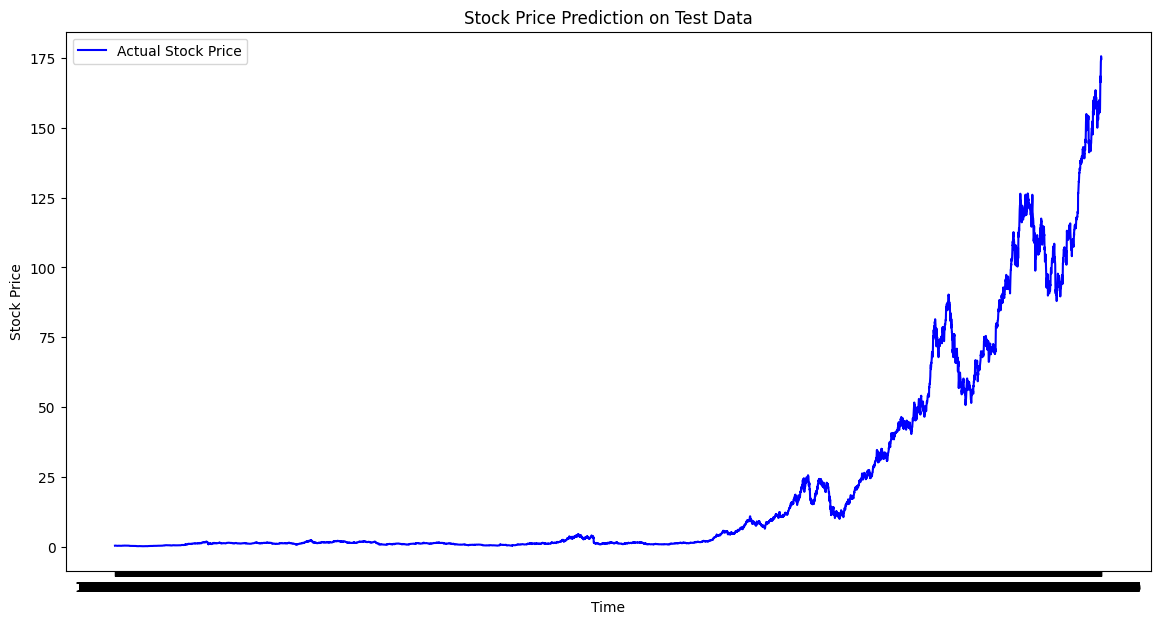

In [41]:
plt.figure(figsize=(14, 7))
plt.plot(dataset["Date"], dataset["Close"], color='blue', label='Actual Stock Price')
plt.title('Stock Price Prediction on Test Data')
plt.xlabel('Time')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

In [42]:
dataset.drop(columns=["OpenInt", "Date"], inplace=True)

In [43]:
training_data = dataset[:6000]
testing_data = dataset[6000:]

# Scale the data to be between 0 and 1
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_train_data = scaler.fit_transform(training_data)
scaled_test_data = scaler.transform(testing_data)


In [44]:
# Define the number of past days to use for prediction
time_steps = 60
X_train = []
y_train = []

# Create the training data sequences
for i in range(time_steps, len(scaled_train_data)):
    # X_train will contain the last 60 days of data (all 5 features)
    X_train.append(scaled_train_data[i-time_steps:i, :])
    # y_train will contain the 'Close' price of the 61st day
    # The 'Close' price is at index 3 in our scaled_data
    y_train.append(scaled_train_data[i, 3])

# Convert to NumPy arrays
X_train, y_train = np.array(X_train), np.array(y_train)


X_test = []
y_test = []

for i in range(time_steps, len(scaled_test_data)):
    X_test.append(scaled_test_data[i-time_steps:i, :])
    y_test.append(scaled_test_data[i, 3])

X_test, y_test = np.array(X_test), np.array(y_test)

print("Data successfully split and prepared.")
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Data successfully split and prepared.
X_train shape: (5940, 60, 5)
X_test shape: (2304, 60, 5)
y_train shape: (5940,)
y_test shape: (2304,)


In [106]:
# Build the LSTM model
model = Sequential()

# First LSTM layer with Dropout
model.add(LSTM(units=150))

# Dense layer for the output
model.add(Dense(units=1))

# Compile the model
# Optimizer: 'adam' is a good default choice.
# Loss function: 'mean_squared_error' is standard for regression problems like this.
model.compile(optimizer='adam', loss='mean_squared_error', metrics=['accuracy'])

# Display the model's architecture
model.summary()

Model: "sequential_18"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_52 (LSTM)                  │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [107]:
# Train the model
print("Training the model...")
history = model.fit(X_train, y_train, epochs=25, batch_size=32)
print("Model training complete.")

Training the model...
Epoch 1/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 3.2139e-04 - loss: 0.0023
Epoch 2/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 3.2139e-04 - loss: 1.4121e-04
Epoch 3/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 3.2139e-04 - loss: 1.2670e-04
Epoch 4/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 20ms/step - accuracy: 3.2139e-04 - loss: 1.1105e-04
Epoch 5/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 3.2139e-04 - loss: 9.9100e-05
Epoch 6/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - accuracy: 3.2139e-04 - loss: 9.0649e-05
Epoch 7/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 3.2139e-04 - loss: 8.4655e-05
Epoch 8/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 3.2139e-04 - loss: 8.0302e-05
Epoch 9/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 3.2139e-04 - loss: 7.7034e-05
Epoch 10/25
186/186 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - accuracy: 3.2139e-04 - loss: 7.4478e-05
Epoch 11/25
186/186 ━━━━━━━━━━━

In [108]:
# --- Make predictions on the test data ---
print("Making predictions on the test data...")
predicted_prices_scaled = model.predict(X_test)

Making predictions on the test data...
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step


In [109]:
# --- Inverse transform the predictions and the actual test values ---

# The scaler was fitted on a 2D array with 5 features (O,H,L,C,V).
# To inverse transform, we must provide an array of the same shape.

# 1. Inverse transform the PREDICTED values
# Create a dummy array of zeros with the same shape as the test data
dummy_predictions = np.zeros((len(predicted_prices_scaled), scaled_train_data.shape[1]))
# Place the scaled predictions into the 'Close' price column (index 3)
dummy_predictions[:, 3] = predicted_prices_scaled.flatten()
# Now, inverse transform the entire dummy array
predicted_prices = scaler.inverse_transform(dummy_predictions)[:, 3]


# 2. Inverse transform the ACTUAL values (y_test)
# Create another dummy array for the actual y_test values
dummy_y_test = np.zeros((len(y_test), scaled_train_data.shape[1]))
# Place the scaled y_test values into the 'Close' price column
dummy_y_test[:, 3] = y_test.flatten()
# Now, inverse transform the dummy array
y_test_actual = scaler.inverse_transform(dummy_y_test)[:, 3]

print("Predictions and actual values have been rescaled to their original price format.")

Predictions and actual values have been rescaled to their original price format.


In [110]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# --- Calculate the evaluation metrics ---
mae = mean_absolute_error(y_test_actual, predicted_prices)
mse = mean_squared_error(y_test_actual, predicted_prices)
rmse = np.sqrt(mse)

print("\n--- Model Evaluation Metrics ---")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Mean Squared Error (MSE): ${mse:.2f}")
print(f"Root Mean Squared Error (RMSE): ${rmse:.2f}")
print("------------------------------------")
print(f"\nInterpretation: The RMSE value of ${rmse:.2f} means that, on average, the model's prediction for the closing price was about ${rmse:.2f} off from the actual closing price on the test data.")


--- Model Evaluation Metrics ---
Mean Absolute Error (MAE): $4.30
Mean Squared Error (MSE): $41.09
Root Mean Squared Error (RMSE): $6.41
------------------------------------

Interpretation: The RMSE value of $6.41 means that, on average, the model's prediction for the closing price was about $6.41 off from the actual closing price on the test data.


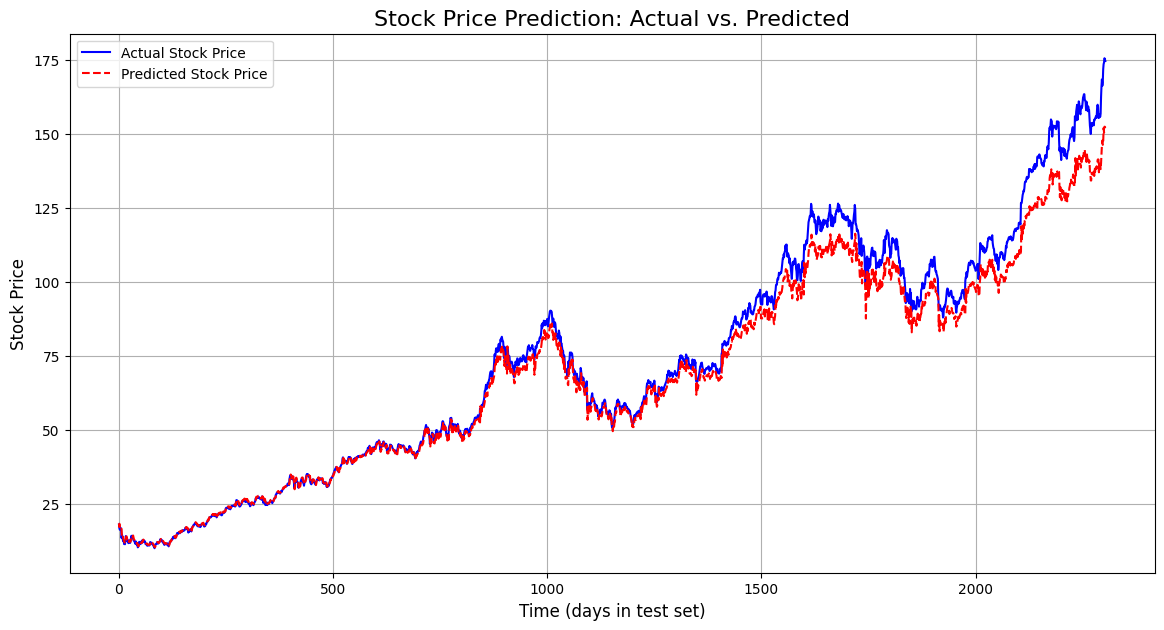

In [111]:
import matplotlib.pyplot as plt

# --- Plot the actual vs. predicted prices ---
plt.figure(figsize=(14, 7))
plt.plot(y_test_actual, color='blue', label='Actual Stock Price')
plt.plot(predicted_prices, color='red', label='Predicted Stock Price', linestyle='--')
plt.title('Stock Price Prediction: Actual vs. Predicted', fontsize=16)
plt.xlabel('Time (days in test set)', fontsize=12)
plt.ylabel('Stock Price', fontsize=12)
plt.legend()
plt.grid(True)
plt.show()